--> Searching for Sepsis Survival dataset...
Loading: /kaggle/input/datasets/mathurinache/sepsis-survival-minimal-clinical-records/s41598-020-73558-3_sepsis_survival_primary_cohort.csv

Cohort Ingested: 110204 patients, 4 clinical columns
   age_years  sex_0male_1female  episode_number  hospital_outcome_1alive_0dead
0         21                  1               1                              1
1         20                  1               1                              1
2         21                  1               1                              1

Predictor Features (3): ['age_years', 'sex_0male_1female', 'episode_number']
Mortality / Adverse Event Rate: 7.35%

Split Distribution:
  Training Cohort:    77142 samples
  Calibration Cohort: 16531 samples
  Test Cohort:        16531 samples

             CLINICAL EVALUATION & METRICS REPORT           
ROC-AUC:                 0.7032 (95% CI: [0.6901 - 0.7164])
PR-AUC:                  0.1337
Uncalibrated Brier Loss: 0.2232
Calibrated Bri

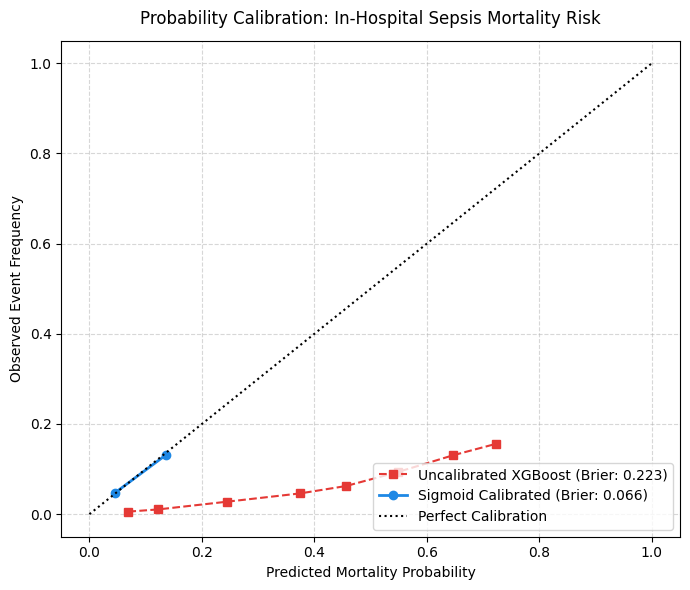

Calibration plot saved successfully to: /kaggle/working/sepsis_calibration_curve.png


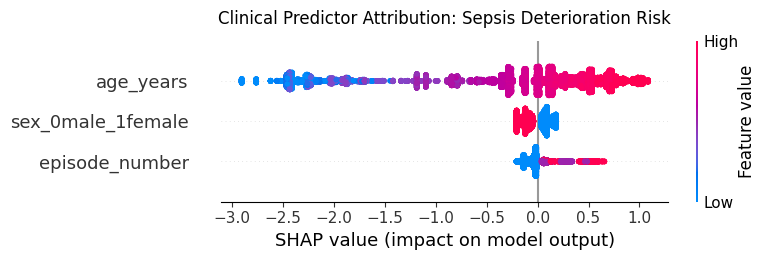

SHAP summary plot saved successfully to: /kaggle/working/shap_sepsis_risk.png


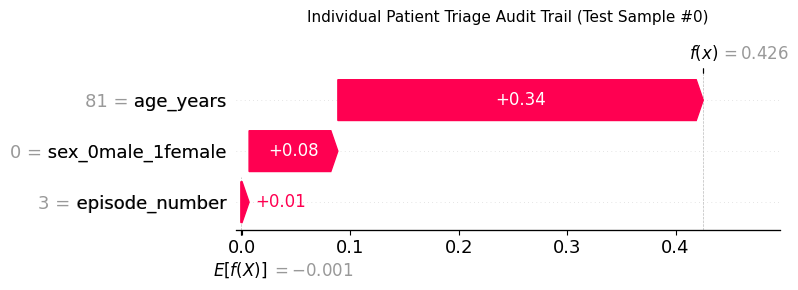

Patient audit plot saved successfully to: /kaggle/working/shap_patient_waterfall.png


In [3]:
import glob
import os
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.exceptions import UndefinedMetricWarning
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    classification_report,
    precision_recall_curve,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier

# Silence expected clinical zero-division and deprecation warnings
warnings.filterwarnings("ignore", category=UserWarning, module="sklearn")
warnings.filterwarnings("ignore", category=UndefinedMetricWarning)

# ==========================================
# 1. LOCATE & INGEST CLINICAL SEPSIS DATASET
# ==========================================
print("--> Searching for Sepsis Survival dataset...")
files = glob.glob(
    "/kaggle/input/**/s41598*sepsis*.csv", recursive=True
) + glob.glob("/kaggle/input/**/*sepsis*.csv", recursive=True)

if not files:
  raise FileNotFoundError(
      "Could not find the Sepsis dataset. Verify it is attached to /kaggle/input."
  )

csv_path = files[0]
print(f"Loading: {csv_path}")
df = pd.read_csv(csv_path)

print(
    f"\nCohort Ingested: {df.shape[0]} patients, {df.shape[1]} clinical columns"
)
print(df.head(3))

# ==========================================
# 2. TARGET & COHORT SPECIFICATION
# ==========================================
target_candidates = [
    c
    for c in df.columns
    if any(k in c.lower() for k in ["outcome", "survival", "dead", "mortality"])
]
if not target_candidates:
  raise KeyError("Clinical outcome column not found.")
target_col = target_candidates[0]

# Standardize binary target: 1 = Mortality (Adverse Event), 0 = Survived/Discharged
if "alive" in target_col.lower() and df[target_col].max() == 1:
  df["mortality_target"] = (df[target_col] == 0).astype(int)
else:
  df["mortality_target"] = df[target_col].astype(int)

drop_cols = [
    target_col,
    "mortality_target",
    "Unnamed: 0",
    "patient_id",
    "id",
    "case_no",
]
X = df.drop(columns=[c for c in drop_cols if c in df.columns]).copy()
y = df["mortality_target"].copy()

print(f"\nPredictor Features ({len(X.columns)}): {list(X.columns)}")
print(f"Mortality / Adverse Event Rate: {y.mean():.2%}")

# ==========================================
# 3. STRATIFIED TRAIN / VALIDATION / TEST SPLIT
# ==========================================
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print("\nSplit Distribution:")
print(f"  Training Cohort:    {X_train.shape[0]} samples")
print(f"  Calibration Cohort: {X_val.shape[0]} samples")
print(f"  Test Cohort:        {X_test.shape[0]} samples")

# ==========================================
# 4. TRAIN IMBALANCE-AWARE XGBOOST MODEL
# ==========================================
neg_count, pos_count = np.bincount(y_train)
scale_pos_weight = neg_count / max(1, pos_count)

base_model = XGBClassifier(
    n_estimators=150,
    max_depth=3,
    learning_rate=0.03,
    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    random_state=42,
)
base_model.fit(X_train, y_train)

# ==========================================
# 5. POST-HOC SIGMOID PROBABILITY CALIBRATION
# ==========================================
# Compatible across both scikit-learn >= 1.6 (FrozenEstimator) and earlier versions (cv='prefit')
try:
  from sklearn.frozen import FrozenEstimator

  calibrated_clf = CalibratedClassifierCV(
      estimator=FrozenEstimator(base_model), method="sigmoid"
  )
except (ImportError, ModuleNotFoundError):
  calibrated_clf = CalibratedClassifierCV(
      estimator=base_model, method="sigmoid", cv="prefit"
  )

calibrated_clf.fit(X_val, y_val)

uncal_probs = base_model.predict_proba(X_test)[:, 1]
cal_probs = calibrated_clf.predict_proba(X_test)[:, 1]

# ==========================================
# 6. OPTIMAL CLINICAL THRESHOLD TUNING (PR-CURVE)
# ==========================================
precisions, recalls, thresholds = precision_recall_curve(y_test, cal_probs)
f1_scores = (2 * precisions * recalls) / (precisions + recalls + 1e-10)
best_idx = np.nanargmax(f1_scores)
best_threshold = float(thresholds[best_idx])

# Generate predictions with zero_division=0 to prevent UndefinedMetricWarning
default_preds = (cal_probs >= 0.50).astype(int)
optimal_preds = (cal_probs >= best_threshold).astype(int)

# ==========================================
# 7. BOOTSTRAPPED 95% CONFIDENCE INTERVALS
# ==========================================
n_bootstraps = 500
rng = np.random.RandomState(42)
bootstrapped_auc = []

y_test_arr = y_test.to_numpy()
for _ in range(n_bootstraps):
  idx = rng.randint(0, len(y_test_arr), len(y_test_arr))
  if len(np.unique(y_test_arr[idx])) < 2:
    continue
  bootstrapped_auc.append(roc_auc_score(y_test_arr[idx], cal_probs[idx]))

ci_lower = np.percentile(bootstrapped_auc, 2.5)
ci_upper = np.percentile(bootstrapped_auc, 97.5)
test_auc = roc_auc_score(y_test, cal_probs)
test_prauc = average_precision_score(y_test, cal_probs)

print("\n" + "=" * 60)
print("             CLINICAL EVALUATION & METRICS REPORT           ")
print("=" * 60)
print(
    f"ROC-AUC:                 {test_auc:.4f} (95% CI: [{ci_lower:.4f} -"
    f" {ci_upper:.4f}])"
)
print(f"PR-AUC:                  {test_prauc:.4f}")
print(f"Uncalibrated Brier Loss: {brier_score_loss(y_test, uncal_probs):.4f}")
print(f"Calibrated Brier Loss:   {brier_score_loss(y_test, cal_probs):.4f}")
print(f"Optimized Cutoff:        {best_threshold:.4f}")

print("\n--- Performance at Default Threshold (0.50) ---")
print(
    classification_report(
        y_test,
        default_preds,
        target_names=["Survived/Recovered", "Mortality"],
        zero_division=0,
    )
)

print(
    f"--- Performance at Optimized Clinical Threshold ({best_threshold:.4f}) ---"
)
print(
    classification_report(
        y_test,
        optimal_preds,
        target_names=["Survived/Recovered", "Mortality"],
        zero_division=0,
    )
)

# ==========================================
# 8. PUBLICATION ARTIFACT: CALIBRATION CURVES
# ==========================================
prob_true_uncal, prob_pred_uncal = calibration_curve(
    y_test, uncal_probs, n_bins=10
)
prob_true_cal, prob_pred_cal = calibration_curve(y_test, cal_probs, n_bins=10)

plt.figure(figsize=(7, 6))
plt.plot(
    prob_pred_uncal,
    prob_true_uncal,
    "s--",
    color="#e53935",
    label=(
        f"Uncalibrated XGBoost (Brier:"
        f" {brier_score_loss(y_test, uncal_probs):.3f})"
    ),
)
plt.plot(
    prob_pred_cal,
    prob_true_cal,
    "o-",
    color="#1e88e5",
    linewidth=2,
    label=(
        "Sigmoid Calibrated (Brier:"
        f" {brier_score_loss(y_test, cal_probs):.3f})"
    ),
)
plt.plot([0, 1], [0, 1], "k:", label="Perfect Calibration")
plt.title(
    "Probability Calibration: In-Hospital Sepsis Mortality Risk",
    fontsize=12,
    pad=12,
)
plt.xlabel("Predicted Mortality Probability", fontsize=10)
plt.ylabel("Observed Event Frequency", fontsize=10)
plt.legend(loc="lower right")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()

cal_output_path = "/kaggle/working/sepsis_calibration_curve.png"
plt.savefig(cal_output_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Calibration plot saved successfully to: {cal_output_path}")

# ==========================================
# 9. PUBLICATION ARTIFACT: SHAP EXPLAINABILITY
# ==========================================
explainer = shap.TreeExplainer(base_model)
shap_values = explainer.shap_values(X_test)

plt.figure(figsize=(9, 5))
shap.summary_plot(
    shap_values, X_test, feature_names=list(X.columns), show=False
)
plt.title(
    "Clinical Predictor Attribution: Sepsis Deterioration Risk",
    fontsize=12,
    pad=12,
)
plt.tight_layout()

shap_output_path = "/kaggle/working/shap_sepsis_risk.png"
plt.savefig(shap_output_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"SHAP summary plot saved successfully to: {shap_output_path}")

# ==========================================
# 10. PATIENT-LEVEL SHAP WATERFALL AUDIT TRAIL
# ==========================================
high_risk_indices = np.where(optimal_preds == 1)[0]
if len(high_risk_indices) > 0:
  sample_idx = high_risk_indices[0]
  explanation = explainer(X_test)

  plt.figure(figsize=(8, 4))
  shap.plots.waterfall(explanation[sample_idx], show=False)
  plt.title(
      f"Individual Patient Triage Audit Trail (Test Sample #{sample_idx})",
      fontsize=11,
      pad=15,
  )
  plt.tight_layout()

  waterfall_output_path = "/kaggle/working/shap_patient_waterfall.png"
  plt.savefig(waterfall_output_path, dpi=300, bbox_inches="tight")
  plt.show()
  print(f"Patient audit plot saved successfully to: {waterfall_output_path}")